# 06 · The Agent

So far we have **calculators** (exact math), **rules** (the answer key), and **retrieval** (search over the Selling Guide).
This notebook gives the first two pieces of real work to an LLM:

1. **Tools**: wrap our calculators and the guide search so an LLM can call them
2. **Tool calling**: watch the LLM decide *which* tool it needs
3. **A hand-written loop**: ask → run tools → ask again, until it answers
4. **LangGraph**: the same loop as a graph, plus a system prompt
5. **Sarah (A007)**: the agent underwrites a full applicant file

The model is `nvidia/nemotron-3-super-120b-a12b`, served free by NVIDIA Build. The key lives in `.env` as `NVIDIA_API_KEY`.

## Setup

In [39]:
import sys
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_nvidia_ai_endpoints import ChatNVIDIA
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.utils.function_calling import convert_to_openai_tool
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition

from mortgage_agent.schemas import Applicant
from mortgage_agent.retrieval import retrieve
from mortgage_agent.tools import ltv, dti, funds_to_close, reserves_months, add_years, search_guide

load_dotenv()

MODEL = "nvidia/nemotron-3-super-120b-a12b"
llm = ChatNVIDIA(model=MODEL, temperature=0, max_tokens=4096)

tools = [search_guide, ltv, dti, funds_to_close, reserves_months, add_years]
tools_by_name = {t.name: t for t in tools}
llm_with_tools = llm.bind_tools(tools)

/tmp/ipykernel_3990/2435711151.py:22: DeprecationWarning: The 'max_tokens' parameter is deprecated and will be removed in a future version. Please use 'max_completion_tokens' instead.
  llm = ChatNVIDIA(model=MODEL, temperature=0, max_tokens=4096)


## 1. Tools are menu cards

`@tool` turns a plain function into an object with a **name**, a **description** (the docstring), and **arguments**.
The LLM never sees our code. It only sees this card.

In [2]:
print(type(ltv))
print(ltv.name)
print(ltv.description)
print(ltv.args)
print(ltv.invoke({"loan_amount": 320000, "property_value": 400000}))

<class 'langchain_core.tools.structured.StructuredTool'>
ltv
Loan-to-value ratio as a percentage: loan amount divided by property value, times 100.
{'loan_amount': {'title': 'Loan Amount', 'type': 'number'}, 'property_value': {'title': 'Property Value', 'type': 'number'}}
80.0


This is the exact JSON the LLM receives for the `ltv` tool:

In [3]:
print(json.dumps(convert_to_openai_tool(ltv), indent=2))

{
  "type": "function",
  "function": {
    "name": "ltv",
    "description": "Loan-to-value ratio as a percentage: loan amount divided by property value, times 100.",
    "parameters": {
      "properties": {
        "loan_amount": {
          "type": "number"
        },
        "property_value": {
          "type": "number"
        }
      },
      "required": [
        "loan_amount",
        "property_value"
      ],
      "type": "object"
    }
  }
}


Each calculator tool gives the same answers as `calculators.py`:

In [4]:
print(dti.args)
print(dti.invoke({"housing_payment": 2420, "monthly_debts": [450, 120], "monthly_income": 8500}))
print(funds_to_close.invoke({"property_value": 400000, "loan_amount": 320000, "closing_costs": 9000}))
print(reserves_months.invoke({"available_funds": 55000, "cash_to_close": 89000, "monthly_pitia": 2420}))
print(reserves_months.invoke({"available_funds": 95000, "cash_to_close": 89000, "monthly_pitia": 2420}))
print(add_years.invoke({"start_date": "2022-10-30", "years": 4}))
print(add_years.invoke({"start_date": "2024-02-29", "years": 1}))

{'housing_payment': {'title': 'Housing Payment', 'type': 'number'}, 'monthly_debts': {'items': {'type': 'number'}, 'title': 'Monthly Debts', 'type': 'array'}, 'monthly_income': {'title': 'Monthly Income', 'type': 'number'}}
35.18
89000.0
-14.05
2.48
2026-10-30
2025-02-28


### The rulebook tool

`search_guide` wraps our retrieval pipeline. First, check that retrieval finds the right sections:

In [5]:
for q in ["large deposit documentation", "Chapter 7 bankruptcy waiting period", "gift from parents"]:
    print(q, "→", [d.metadata["rule_id"] for d in retrieve(q, top_n=3)])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

large deposit documentation → ['B3-4.2-02', 'B3-4.2-02', 'B3-4.2-02']
Chapter 7 bankruptcy waiting period → ['B3-5.3-07', 'B3-5.3-07', 'B3-5.3-07']
gift from parents → ['B3-4.3-04', 'B3-4.3-04', 'B3-4.3-05']


What the LLM actually gets back from one search. Every character here costs tokens, so shorter is better:

In [6]:
result = search_guide.invoke({"query": "large deposit documentation"})
print(len(result), "characters")
print(result[:700])

3797 characters
Fannie Mae Selling Guide, B3-4.2-02: Depository Accounts

loan.  When bank statements (typically covering the most recent two months) are used, the lender must
evaluate large deposits. See B3-4.1-04, Virtual Currency for additional information when a large deposit may be
from virtual currency that was exchanged into U.S. dollars. Requirements for evaluating large deposits vary
based on the transaction type, as shown in the table below.
Transaction Type
Evaluation Requirements
Refinance transactions
Documentation or explanation for large deposits is not required; however,
the lender remains responsible for ensuring that any borrowed funds,
including any related liability, are considered.
Tran


## 2. Tool calling: the LLM picks a tool

`bind_tools` hands the menu cards to the LLM. Now, instead of answering in text, it can reply with an
**order slip** (`tool_calls`) asking us to run a tool.

In [7]:
response = llm_with_tools.invoke("What is the LTV for a $320,000 loan on a $400,000 home?")
print("Text:", repr(response.content))
print("Tool calls:", response.tool_calls)

Text: ''
Tool calls: [{'name': 'ltv', 'args': {'loan_amount': 320000, 'property_value': 400000}, 'id': 'call-06472503-6f1a-4328-aece-55c92b91a71e', 'type': 'tool_call'}]


The LLM only *asks*. **We** run the tool:

In [8]:
if response.tool_calls:
    call = response.tool_calls[0]
    print(tools_by_name[call["name"]].invoke(call["args"]))

80.0


A question that needs no tool gets a plain text answer:

In [9]:
response = llm_with_tools.invoke("What does LTV stand for?")
print("Text:", response.content)
print("Tool calls:", response.tool_calls)

Text: LTV stands for **Loan-to-Value ratio**. It is a key metric in mortgage underwriting that expresses the loan amount as a percentage of the property's value. The formula is:

\[
\text{LTV} = \left( \frac{\text{Loan Amount}}{\text{Property Value}} \right) \times 100
\]

For example, if a borrower takes out a $200,000 loan on a property valued at $250,000, the LTV is 80%. Lenders use LTV to assess risk—higher LTV ratios typically indicate higher risk because the borrower has less equity in the property.
Tool calls: []


A rules question should send it to the guide:

In [10]:
response = llm_with_tools.invoke("Does a $40,000 bank deposit need to be documented for a mortgage?")
print("Tool calls:", response.tool_calls)

Tool calls: [{'name': 'search_guide', 'args': {'query': 'large deposit documentation'}, 'id': 'call-dcb060a4-4776-49a2-8628-e9876416c92d', 'type': 'tool_call'}]


## 3. The agent loop, by hand

An agent is just a loop:

1. Send the conversation to the LLM
2. If it asks for tools, run them and add the results to the conversation (as `ToolMessage`s)
3. Repeat until it answers in text

This pattern is called **ReAct**: Reason, then Act, then Reason again.

In [11]:
def run_agent(question: str, max_steps: int = 10) -> str:
    """Ask the LLM, run any tools it needs, and repeat until it answers."""
    messages = [HumanMessage(question)]
    for step in range(max_steps):
        response = llm_with_tools.invoke(messages)
        messages.append(response)

        if not response.tool_calls:
            return response.content

        for call in response.tool_calls:
            print(f"Step {step + 1}: {call['name']}({call['args']})")
            result = tools_by_name[call["name"]].invoke(call["args"])
            messages.append(ToolMessage(content=str(result), tool_call_id=call["id"]))
    return "Stopped: too many steps."

In [12]:
print(run_agent("What is the LTV for a $320,000 loan on a $400,000 home?"))

Step 1: ltv({'loan_amount': 320000, 'property_value': 400000})
The loan‑to‑value (LTV) ratio is **80 %**.


In [13]:
print(run_agent(
    "A borrower's Chapter 7 bankruptcy was discharged on 2022-10-31. "
    "The new loan closes on 2026-10-30. Is the waiting period met?"
))

Step 1: search_guide({'query': 'Chapter 7 bankruptcy waiting period'})
Step 2: add_years({'start_date': '2022-10-31', 'years': 4})
Based on the Fannie Mae Selling Guide (B3‑5.3‑07), a Chapter 7 bankruptcy requires a **4‑year waiting period** measured from the discharge date.

- Bankruptcy discharge date: **2022‑10‑31**  
- 4‑year waiting period end date: **2026‑10‑31** (calculated with the add_years tool)  
- Proposed loan closing date: **2026‑10‑30**

The closing date is **one day before** the 4‑year anniversary of the discharge. Therefore, the standard waiting period **has not been met**.

*(If the borrower could document extenuating circumstances, a 2‑year waiting period would apply, which would be satisfied by the 2026‑10‑30 closing date. However, no extenuating circumstances were indicated in the scenario.)*


## 4. The same loop with LangGraph

LangGraph draws the loop as a graph:

- **State**: the list of messages (`MessagesState` appends new ones)
- **Nodes**: `llm` (think) and `tools` (act)
- **Edges**: after `llm`, `tools_condition` goes to `tools` or ends. After `tools`, always back to `llm`

The **system prompt** is the underwriter's job description. It is added in front of every LLM call.

In [28]:
SYSTEM_PROMPT = """You are a mortgage underwriter reviewing a purchase loan application against the Fannie Mae Selling Guide, Part B3.

How to work:
- Review the whole file: credit history, debt-to-income, funds to close and reserves, large deposits, and gifts.
- Before applying any rule, look it up with search_guide. Never rely on memory for limits, waiting periods, or documentation requirements.
- Search each topic at most twice. If the guide does not cover something, say so and move on.
- Use the tools for every calculation and every date. Never do arithmetic in your head.
- Cite the rule ID (for example B3-6-02) for every finding.

Project assumptions:
- All loans are underwritten through DU, are fixed-rate, and have one borrower.
- There are no extenuating circumstances.
- The purchase price equals the property value.
- Measure waiting periods up to the closing_date.
- The Eligibility Matrix is not available, so do not check maximum LTV limits.

What the file fields mean:
- monthly_housing_payment is the proposed monthly PITIA.
- monthly_income is what the borrower states; verified_monthly_income is what their documents show.
- months_remaining is null for revolving debt such as credit cards.
- bank_balance already includes any large_deposits listed.
- gifts are not included in bank_balance.

Decisions:
- approve: the file meets every requirement.
- approve with conditions: it meets every requirement once missing documentation is provided.
- decline: it fails a requirement that documentation cannot fix.

Keep your write-up short: one line per check, under 250 words in total. Then finish with exactly these two lines:
DECISION: <approve | approve with conditions | decline>
RULES: <comma-separated rule IDs that caused a decline or condition, or none>"""

In [30]:
def call_llm(state: MessagesState) -> dict:
    """Node: send the whole conversation to the LLM and return its reply."""
    messages = [SystemMessage(SYSTEM_PROMPT)] + state["messages"]
    return {"messages": [llm_with_tools.invoke(messages)]}


builder = StateGraph(MessagesState)
builder.add_node("llm", call_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")

graph = builder.compile()

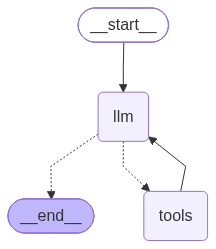

7966

In [16]:
png = graph.get_graph().draw_mermaid_png()
display(Image(png))
Path("../docs").mkdir(exist_ok=True)
Path("../docs/agent_graph.png").write_bytes(png)

In [17]:
import re

DECISIONS = {"approve", "approve with conditions", "decline"}
RULE_ID = r"B3-\d+(?:\.\d+)*-\d+"


def parse_decision(text: str) -> dict:
    """Read the DECISION and RULES lines from the agent's final answer."""
    text = text.replace("\u2011", "-").replace("\u2010", "-").replace("\u2013", "-")

    decision_line = re.search(r"DECISION:\s*(.+)", text, re.IGNORECASE)
    rules_line = re.search(r"RULES:\s*(.+)", text, re.IGNORECASE)

    decision = decision_line.group(1).strip().strip("*. ").lower() if decision_line else None
    rule_ids = sorted(set(re.findall(RULE_ID, rules_line.group(1)))) if rules_line else []

    return {"decision": decision if decision in DECISIONS else None, "rule_ids": rule_ids}

The bankruptcy question again, now through the graph:

In [18]:
result = graph.invoke(
    {"messages": [HumanMessage(
        "A borrower's Chapter 7 bankruptcy was discharged on 2022-10-31. "
        "The new loan closes on 2026-10-30. Is the waiting period met?"
    )]},
    config={"recursion_limit": 20},
)

for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

A borrower's Chapter 7 bankruptcy was discharged on 2022-10-31. The new loan closes on 2026-10-30. Is the waiting period met?
================================== Ai Message ==================================
Tool Calls:
  search_guide (call-d07a3cfb-0038-421a-9ff1-32d55533b3fd)
 Call ID: call-d07a3cfb-0038-421a-9ff1-32d55533b3fd
  Args:
    query: Chapter 7 bankruptcy waiting period
================================= Tool Message =================================
Name: search_guide

Fannie Mae Selling Guide, B3-5.3-07: Significant Derogatory Credit Events — Waiting Periods and Re-establishing Credit

Credit Events in the Credit Report above for additional information.
Summary — All Waiting Period Requirements
The following table summarizes the waiting period requirements for all significant derogatory credit events.
Derogatory Event
Waiting Period
Requirements
Waiting Period with
Extenuating Circumstances
B

## 5. Sarah (A007): a full applicant file

The agent sees the whole file **except** `expected`, which is the answer key.
Sarah's correct answer is **approve with conditions (B3-4.2-02)**: her $40,000 deposit is undocumented, and she needs it to close.

In [19]:
def applicant_file(applicant: Applicant) -> str:
    """The applicant's file as the agent sees it: everything except the answer key."""
    return applicant.model_dump_json(exclude={"expected"})


sarah = Applicant.model_validate_json(Path("../data/applicants/A007.json").read_text())
file_text = applicant_file(sarah)

print(file_text)
print("Answer key hidden:", "expected" not in file_text)

{"applicant_id":"A007","name":"Sarah Chen","closing_date":"2026-10-30","loan":{"amount":320000.0,"property_value":400000.0,"monthly_housing_payment":2420.0,"estimated_closing_costs":9000.0,"property_type":"1-unit","occupancy":"principal residence","underwriting":"DU"},"income":{"employer":"Northwind Logistics","monthly_income":8500.0,"verified_monthly_income":8500.0,"years_employed":3.0,"pay_frequency":"biweekly","self_employed":false},"debts":[{"kind":"auto loan","monthly_payment":450.0,"balance":9000.0,"months_remaining":20},{"kind":"credit card","monthly_payment":120.0,"balance":3500.0,"months_remaining":null}],"credit":{"score":705,"bankruptcy_chapter":null,"bankruptcy_discharge_date":null,"foreclosure_date":null},"assets":{"bank_balance":95000.0,"retirement_balance":0.0,"large_deposits":[{"amount":40000.0,"deposit_date":"2026-09-01","source_documented":false}],"gifts":[]}}
Answer key hidden: True


Run the agent and watch each step as it happens. For every LLM call we print the **input tokens**
(the conversation snowballs, so this number grows) and which tools it asked for.

In [20]:
for step in graph.stream(
    {"messages": [HumanMessage(f"Underwrite this application:\n\n{file_text}")]},
    config={"recursion_limit": 30},
    stream_mode="updates",
):
    for node, update in step.items():
        for msg in update["messages"]:
            if node == "llm":
                tokens = msg.usage_metadata["input_tokens"] if msg.usage_metadata else "?"
                calls = [f"{c['name']}{c['args']}" for c in msg.tool_calls]
                print(f"LLM  | input tokens: {tokens} | {calls or 'FINAL ANSWER'}")
                if not msg.tool_calls:
                    print("\n" + msg.content)
            else:
                print(f"TOOL | {msg.name}: {len(msg.content)} chars")

LLM  | input tokens: 1807 | ["search_guide{'query': 'DU credit score minimum'}"]
TOOL | search_guide: 4656 chars
LLM  | input tokens: 3567 | ["search_guide{'query': 'DU debt-to-income ratio limits'}"]
TOOL | search_guide: 4579 chars
LLM  | input tokens: 4783 | ["search_guide{'query': 'DU reserves requirements'}"]
TOOL | search_guide: 4508 chars
LLM  | input tokens: 5889 | ["search_guide{'query': 'DU reserve requirements credit score LTV'}"]
TOOL | search_guide: 4628 chars
LLM  | input tokens: 7301 | ["search_guide{'query': 'large deposit definition'}"]
TOOL | search_guide: 4537 chars
LLM  | input tokens: 8514 | ["ltv{'loan_amount': 320000, 'property_value': 400000}"]
TOOL | ltv: 4 chars
LLM  | input tokens: 9481 | ["dti{'housing_payment': 2420, 'monthly_debts': [450, 120], 'monthly_income': 8500}"]
TOOL | dti: 5 chars
LLM  | input tokens: 9575 | ["funds_to_close{'property_value': 400000, 'loan_amount': 320000, 'closing_costs': 9000}"]
TOOL | funds_to_close: 7 chars
LLM  | input tokens:

In [21]:
from langchain_core.messages import HumanMessage

result = graph.invoke(
    {"messages": [HumanMessage(f"Underwrite this application:\n\n{file_text}")]},
    config={"recursion_limit": 30},
)
final = result["messages"][-1].content

print(final[-300:])
print("\nParsed:  ", parse_decision(final))
print("Expected:", sarah.expected)

cash to close. Therefore, the loan is acceptable **provided** the borrower supplies documentation for the $40,000 deposit.

All other factors (bankruptcy, foreclosure, gifts, etc.) are not applicable.

**Decision**  
DECISION: approve with conditions  
RULES: B3-5.1-01, B3-6-02, B3-4.1-01, B3-4.2-02

Parsed:   {'decision': 'approve with conditions', 'rule_ids': ['B3-4.1-01', 'B3-4.2-02', 'B3-5.1-01', 'B3-6-02']}
Expected: decision='approve with conditions' reasons=['Undocumented $40,000 deposit must be sourced'] rule_ids=['B3-4.2-02']


In [29]:
import re
import json
import time
from pathlib import Path

from langchain_core.messages import HumanMessage
from mortgage_agent.schemas import Applicant

APPLICANTS_DIR = Path("../data/applicants/generated")
RESULTS_DIR = Path("../results") / MODEL.replace("/", "_")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def run_one(applicant: Applicant) -> dict:
    """Run the agent on one applicant and return its decision, its process, and run statistics"""

    start = time.time()
    result = graph.invoke(
        {"messages": [HumanMessage(f"Underwrite this application;\n\n{applicant_file(applicant)}")]},
        config={"recursion_limit": 40},
    )
    llm_messages = [m for m in result["messages"] if m.type == "ai"]
    final = result["messages"][-1].content

    return {
        "applicant_id": applicant.applicant_id,
        "parsed": parse_decision(final),
        "expected": applicant.expected.model_dump(mode="json"),
        "final_answer": final,
        "tool_calls": [{"name": c["name"], "args": c["args"]} for m in llm_messages for c in m.tool_calls],
        "retrieved_rules": sorted({
            rule
            for m in result["messages"] if m.type == "tool" and m.name == "search_guide"
            for rule in re.findall(r"Selling Guide, (B3-[\d.]+-\d+)", m.content)
        }),
        "llm_calls": len(llm_messages),
        "input_tokens": sum(m.usage_metadata["input_tokens"] for m in llm_messages if m.usage_metadata),
        "seconds": round(time.time() - start, 1),
        "finish_reason": result["messages"][-1].response_metadata.get("finish_reason"),
    }


In [31]:
import json 
import time

from mortgage_agent.schemas import Applicant

paths = sorted(APPLICANTS_DIR.glob("G*.json"))

for i, path in enumerate(paths, 1):
    out = RESULTS_DIR / path.name
    if out.exists():
        continue

    applicant = Applicant.model_validate_json(path.read_text())
    for attempt in range(3):
        try:
            record = run_one(applicant)
            break
        except Exception as e:
            record = {"applicant_id": applicant.applicant_id, "error": f"{type(e).__name__}: {e}"[:500]}
            if "Recursion" in type(e).__name__:
                break
            time.sleep(30 * (attempt + 1))

    out.write_text(json.dumps(record, indent=2))

    got = record.get("parsed", {}).get("decision")
    want = record.get("expected", {}).get("decision")
    mark = "Y" if got == want else "X"
    print(f"[{i}/{len(paths)}] {applicant.applicant_id} | {record.get('seconds', '-')}s | {mark} got={got} want={want}")

[1/120] G001 | 124.1s | Y got=approve want=approve
[3/120] G003 | 76.8s | Y got=approve want=approve
[4/120] G004 | 83.1s | Y got=decline want=decline
[5/120] G005 | 126.6s | Y got=decline want=decline
[6/120] G006 | 62.2s | Y got=approve with conditions want=approve with conditions
[7/120] G007 | 79.6s | Y got=approve with conditions want=approve with conditions
[8/120] G008 | 56.0s | Y got=decline want=decline


KeyboardInterrupt: 

In [26]:
import json
from pathlib import Path

for name in ["G001", "G003"]:
    record = json.loads((RESULTS_DIR / f"{name}.json").read_text())
    print("=" * 60, name, "| llm calls:", record["llm_calls"])
    print(record["final_answer"][-500:])

============================================================ G001 | llm calls: 15
 that after the waiting period is met, the borrower must have re‑established credit as evidenced by the credit report. The borrower’s credit score is 736 and they have an active tradeline (credit card). This demonstrates re‑established credit. Additionally, **B3‑5.4‑01** confirms that because the borrower has at least one credit account, they possess traditional credit, satisfying the traditional‑credit requirement.

4. **Debt‑to‑Income Ratio (DTI)**:  
   - Monthly housing payment (PITIA) = $2,
============================================================ G003 | llm calls: 5



In [ ]:
import json
import time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

from mortgage_agent.retrieval import retrieve
from mortgage_agent.schemas import Applicant

WORKERS = 3


def is_done(path: Path) -> bool:
    """True if this applicant already has a successful result file."""
    out = RESULTS_DIR / path.name
    return out.exists() and "error" not in json.loads(out.read_text())


def process(path: Path) -> dict:
    """Run one applicant (with retries) and save its result file."""
    applicant = Applicant.model_validate_json(path.read_text())
    for attempt in range(3):
        try:
            record = run_one(applicant)
            break
        except Exception as e:
            record = {"applicant_id": applicant.applicant_id, "error": f"{type(e).__name__}: {e}"[:500]}
            if "Recursion" in type(e).__name__:
                break
            time.sleep(30 * (attempt + 1))

    (RESULTS_DIR / path.name).write_text(json.dumps(record, indent=2))
    return record


retrieve("warm up")

todo = [p for p in sorted(APPLICANTS_DIR.glob("G*.json")) if not is_done(p)]
print(f"{len(todo)} applicants to run with {WORKERS} workers\n")

start = time.time()
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    futures = [pool.submit(process, p) for p in todo]
    for n, future in enumerate(as_completed(futures), 1):
        record = future.result()
        got = record.get("parsed", {}).get("decision")
        want = record.get("expected", {}).get("decision")
        mark = "Y" if got == want else "X"
        print(f"[{n}/{len(todo)}] {record['applicant_id']} | {record.get('seconds', '-')}s | {mark} got={got} want={want}")

print(f"\nDone in {(time.time() - start) / 60:.1f} minutes")

23 applicants to run with 3 workers

[1/23] G099 | -s | Y got=None want=None
[2/23] G100 | -s | Y got=None want=None
[3/23] G098 | -s | Y got=None want=None


In [33]:
import json

for name in ["G098", "G119"]:
    print(name, json.loads((RESULTS_DIR / f"{name}.json").read_text())["error"])

G098 Exception: [429] Too Many Requests
{'status': 429, 'title': 'Too Many Requests'}
G119 Exception: [429] Too Many Requests
{'status': 429, 'title': 'Too Many Requests'}


In [34]:
from langchain_nvidia_ai_endpoints import ChatNVIDIA

test = ChatNVIDIA(model=MODEL, temperature=0, max_tokens=20)
print(test.invoke("Say OK").content)

/tmp/ipykernel_3990/2611601636.py:3: DeprecationWarning: The 'max_tokens' parameter is deprecated and will be removed in a future version. Please use 'max_completion_tokens' instead.
  test = ChatNVIDIA(model=MODEL, temperature=0, max_tokens=20)


In [38]:
from langchain_nvidia_ai_endpoints import ChatNVIDIA

test = ChatNVIDIA(model=MODEL, temperature=0, max_completion_tokens=300)
print(repr(test.invoke("Say OK").content))

'OK'


In [37]:
import json

for name in ["G015", "G018"]:
    record = json.loads((RESULTS_DIR / f"{name}.json").read_text())
    print("=" * 70)
    print(name, "| want:", record["expected"]["decision"], record["expected"]["rule_ids"])
    print("tools:", [c["name"] for c in record["tool_calls"]])
    print(record["final_answer"])

G015 | want: decline ['B3-4.1-01']
tools: ['ltv', 'dti', 'funds_to_close', 'search_guide', 'search_guide', 'search_guide', 'search_guide', 'search_guide', 'search_guide', 'search_guide', 'search_guide']
- LTV calculated as 75% (loan amount/property value).  
- DTI ratio 34.65% ≤ 50% maximum for DU underwriting (B3-6-02).  
- Credit history shows no bankruptcy or foreclosure; no waiting periods applicable.  
- Funds to close: cash to close $157,209 (funds_to_close); available liquid assets $130,600 (bank balance) insufficient by $26,609 for closing alone (B3-4.4-01).  
- Reserves required: 2 months PITIA = $6,800 for second home (B3-4.1-01); total funds to be verified $164,009 > available assets $130,600, shortfall $33,409 (B3-4.4-01, B3-4.1-01).  
- Large deposits: none reported; no documentation needed (B3-4.2-02).  
- Gifts: none reported; no documentation needed (B3-4.3-04).  
- Condition: borrower must verify additional liquid assets of at least $33,409 to cover funds to close and 